# Grid Search Analysis: GRN Inference Performance (Detailed)
This notebook analyzes the performance metrics without aggregating over different parameter configurations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set plotting style
sns.set_theme(style='whitegrid', context='talk')
os.makedirs('images/detailed', exist_ok=True)


In [2]:
network_type = "ER" # "ER" or "SF"

# Load data
if network_type == "ER":
    df = pd.read_csv('results/grid_results_er/performance_metrics.csv')
elif network_type == "SF":
    df = pd.read_csv('results/grid_results/performance_metrics.csv')
# We no longer drop duplicates because we want to keep all trials for seaborn to calculate confidence intervals
# df = df.drop_duplicates(subset=['dt_meas', 'M_pairs', 't_window_start', 't_window_end', 'N'], keep='last')

def label_window(row):
    if row['t_window_start'] == 0.0:
        return 'T'
    else:
        return 'S'
        
df['Regime'] = df.apply(label_window, axis=1)

# select rows where M <= 1000
df = df[df['M_pairs'] <= 1000]
df = df.reset_index(drop=True)

numeric_cols = ['TP', 'FP', 'FN', 'TN', 'TPR (Recall)', 'FPR', 'Precision', 'F1-Score', 'SHD']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("Columns:", ', '.join(df.columns))


Columns: trial, dt_meas, M_pairs, t_window_start, t_window_end, N, m, p, Regime, TP, FP, FN, TN, TPR (Recall), FPR, Precision, F1-Score, SHD, AUROC, AUPRC, AUPRC_Ratio, AUPRC_Norm, MSE, Pearson, Spearman, RBO, Wasserstein


In [18]:
if network_type == "ER":
    df_provv = df[df['dt_meas']==0.05]
    sns.lineplot(df_provv, x="p", y="AUPRC_Ratio", hue="N", palette="dark", marker="o")
    plt.yscale("log")
    plt.tight_layout()
    plt.show()

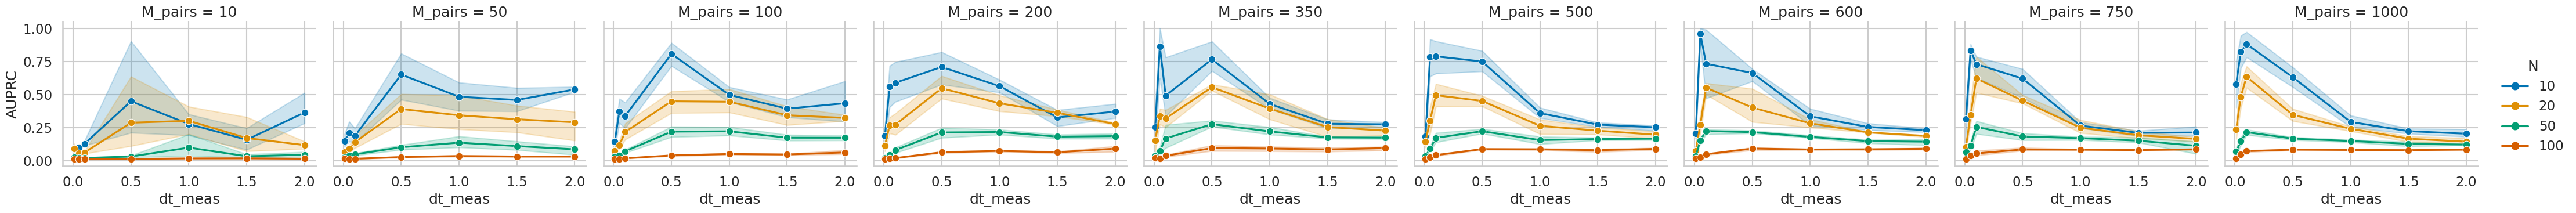

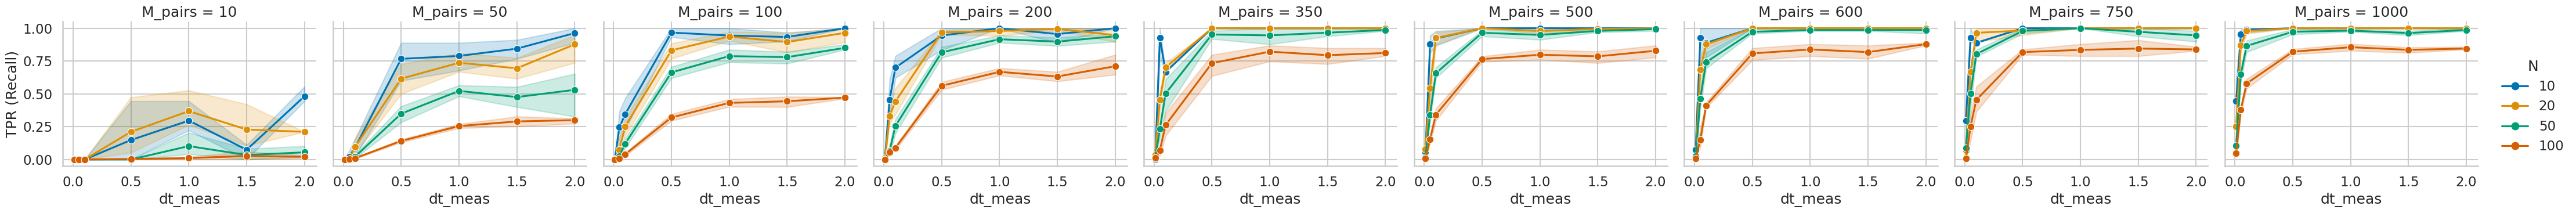

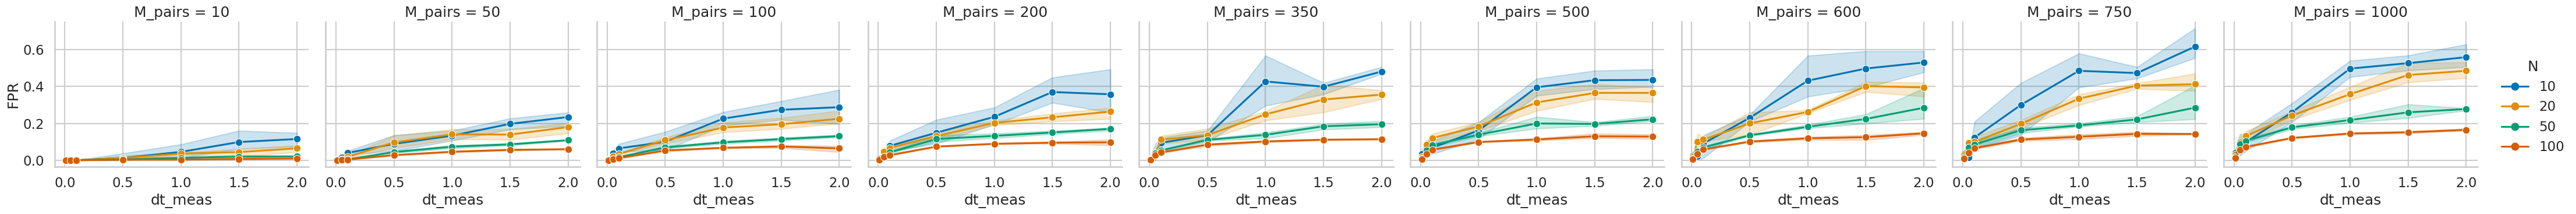

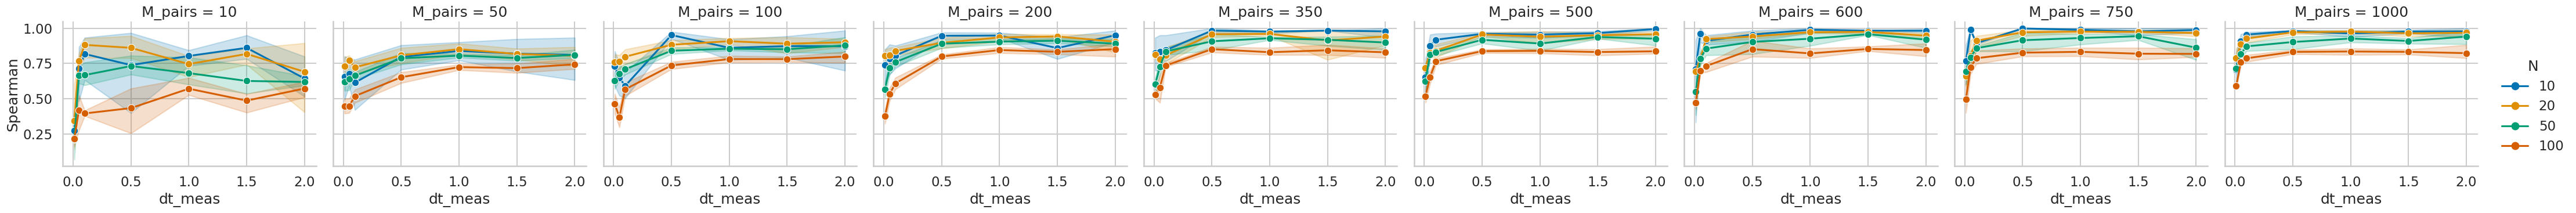

In [19]:
# Plot F1-Score vs M_pairs. We use a FacetGrid to separate dt_meas (columns) and Regime (rows).

g = sns.relplot(
    data=df[df['Regime']=='T'], x='dt_meas', y='AUPRC', hue='N',
    col='M_pairs', kind='line', err_style='band', marker='o',
     height=4, aspect=1.2, palette='colorblind'
)
g = sns.relplot(
    data=df[df['Regime']=='T'], x='dt_meas', y='TPR (Recall)', hue='N',
    col='M_pairs', kind='line', err_style='band', marker='o',
     height=4, aspect=1.2, palette='colorblind'
)
g = sns.relplot(
    data=df[df['Regime']=='T'], x='dt_meas', y='FPR', hue='N',
    col='M_pairs', kind='line', err_style='band', marker='o',
     height=4, aspect=1.2, palette='colorblind'
)
g = sns.relplot(
    data=df[df['Regime']=='T'], x='dt_meas', y='Spearman', hue='N',
    col='M_pairs', kind='line', err_style='band', marker='o',
     height=4, aspect=1.2, palette='colorblind'
)
#g.set(xlim=(0, 1100))
g.savefig('images/detailed/performance_vs_M_faceted.png', dpi=300, bbox_inches='tight')
plt.show()


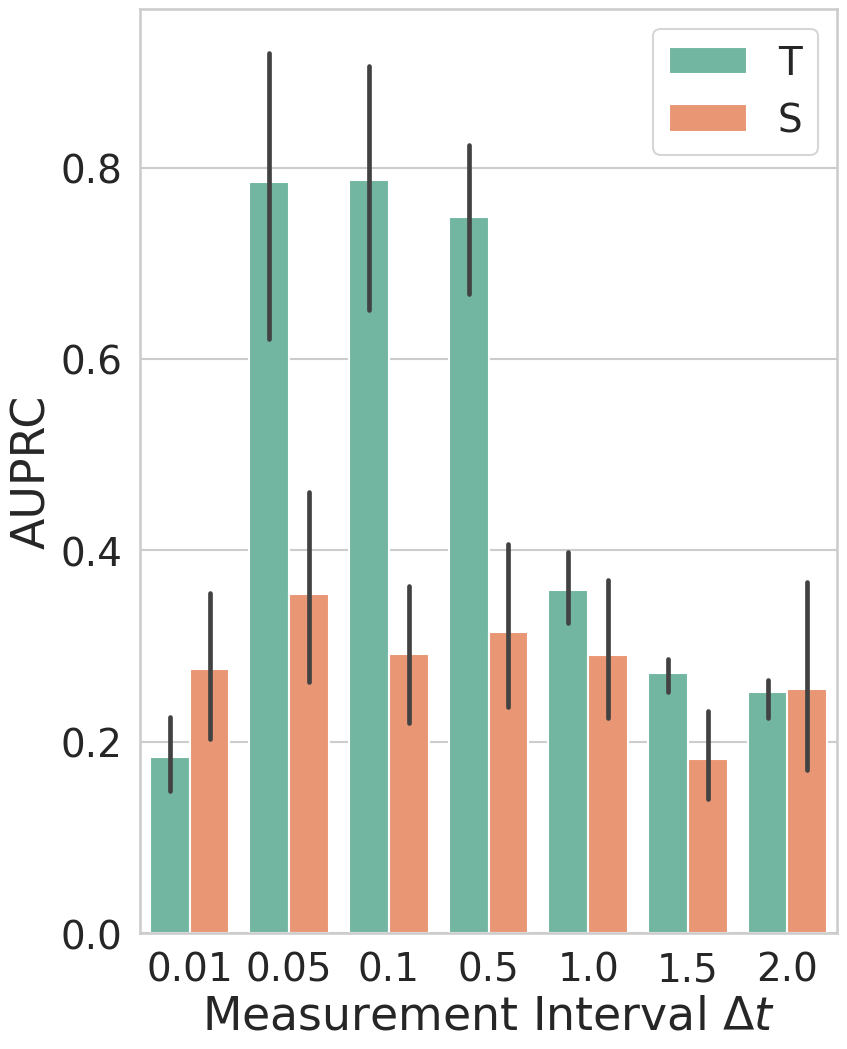

In [20]:
# Choose a specific configuration to compare transient vs stationary: M_pairs=500, dt_meas=0.05
fixed_M = 500
fixed_dt = 0.05
df_subset = df[(df['M_pairs'] == fixed_M) & (df['N'] == 10)]

fig, ax = plt.subplots(figsize=(9, 12))
fontsize = 28

sns.barplot(data=df_subset, x='dt_meas', y='AUPRC', hue='Regime', palette='Set2', ax=ax)
ax.set_xlabel(r'Measurement Interval $\Delta t$', fontsize=fontsize+5)
ax.set_ylabel('AUPRC', fontsize=fontsize+5)
ax.tick_params(axis='both', which='major', labelsize=fontsize)

plt.legend(loc='upper right', fontsize=fontsize)
plt.savefig('images/detailed/transient_vs_stationary_fixed.png', dpi=300, bbox_inches='tight')
plt.show()


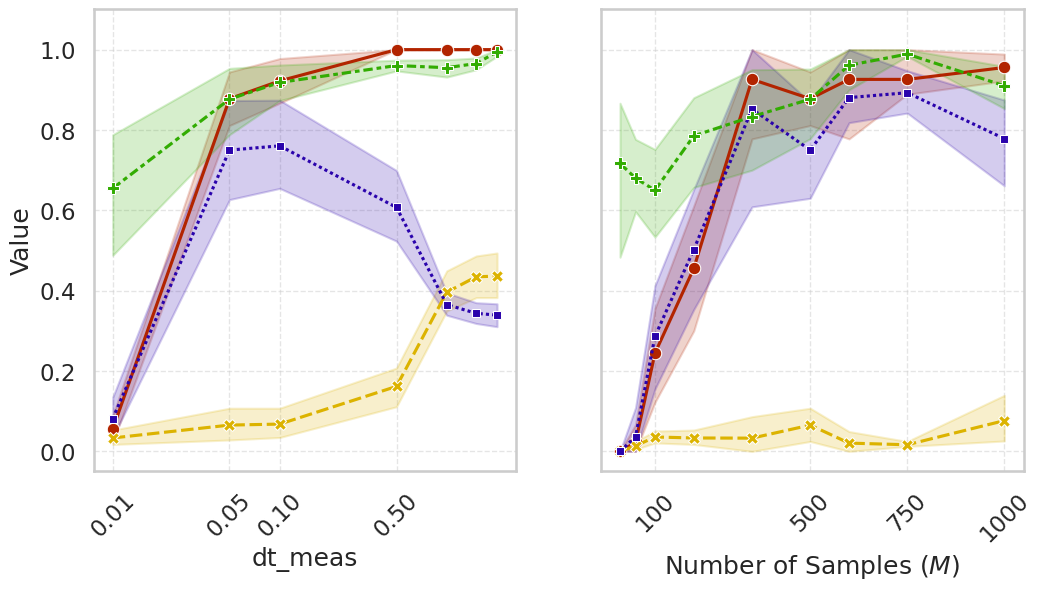

In [21]:
# Choose a specific configuration: M_pairs=500, Regime=Transient, N=10
fixed_Regime = 'T'
fixed_N = 10
df_dt = df[(df['M_pairs'] == 500) & (df['Regime'] == fixed_Regime) & (df['N'] == fixed_N)]

# Include MAE in the comparison
df_melted = df_dt.melt(
    id_vars=['dt_meas'],
    value_vars=['TPR (Recall)', 'FPR', 'F1-Score', 'Spearman'],
    var_name='Metric',
    value_name='Score'
)

fig, axs = plt.subplots(1, 2, figsize=(12, 6))

ax = axs[0]

sns.lineplot(
    data=df_melted, x='dt_meas', y='Score',
    hue='Metric', style='Metric',
    markers=True, err_style='band', ax=ax, legend=False,
    palette=["#b22400", "#dcb300", "#2a03ac", "#32ac02"]
)

ax.set_xlabel('dt_meas')
ax.set_ylabel('Value')
ax.set_ylim([-0.05, 1.1])
ax.set_xscale('log')
ax.set_xticks([0.01, 0.05, 0.1, 0.5])
ax.tick_params(axis='x', rotation=45)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.grid(lw=1.0, ls="--", alpha=0.5)
#ax.legend(bbox_to_anchor=(1.5, 1.15), ncol=4)

# Choose a specific configuration: M_pairs=500, Regime=Transient, N=10
fixed_Regime = 'T'
fixed_N = 10
df_dt = df[(df['dt_meas'] == 0.05) & (df['Regime'] == fixed_Regime) & (df['N'] == fixed_N)]

# Include MAE in the comparison
df_melted = df_dt.melt(
    id_vars=['M_pairs'],
    value_vars=['TPR (Recall)', 'FPR', 'F1-Score', 'Spearman'],
    var_name='Metric',
    value_name='Score'
)

ax = axs[1]
sns.lineplot(
    data=df_melted, x='M_pairs', y='Score',
    hue='Metric', style='Metric',
    markers=True, err_style='band', ax=ax, legend=False,
    palette=["#b22400", "#dcb300", "#2a03ac", "#32ac02"]
)

ax.set_xlabel(r'Number of Samples ($M$)')
ax.set_ylabel('')
ax.set_ylim([-0.05, 1.1])
ax.set_xticks([100, 500,750, 1000])
ax.tick_params(axis='x', rotation=45)
ax.set_yticks(np.arange(0,1.1,0.2))
ax.set_yticklabels([])
ax.grid(lw=1.0, ls="--", alpha=0.5)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
#ax.set_title(f'TPR, FPR, F1-Score, and MAE vs dt_meas (Fixed M={fixed_M}, Regime={fixed_Regime}, N={fixed_N})')
#plt.tight_layout()

plt.savefig('images/detailed/metrics_comparison_single_N.png', dpi=300, bbox_inches='tight')
plt.show()

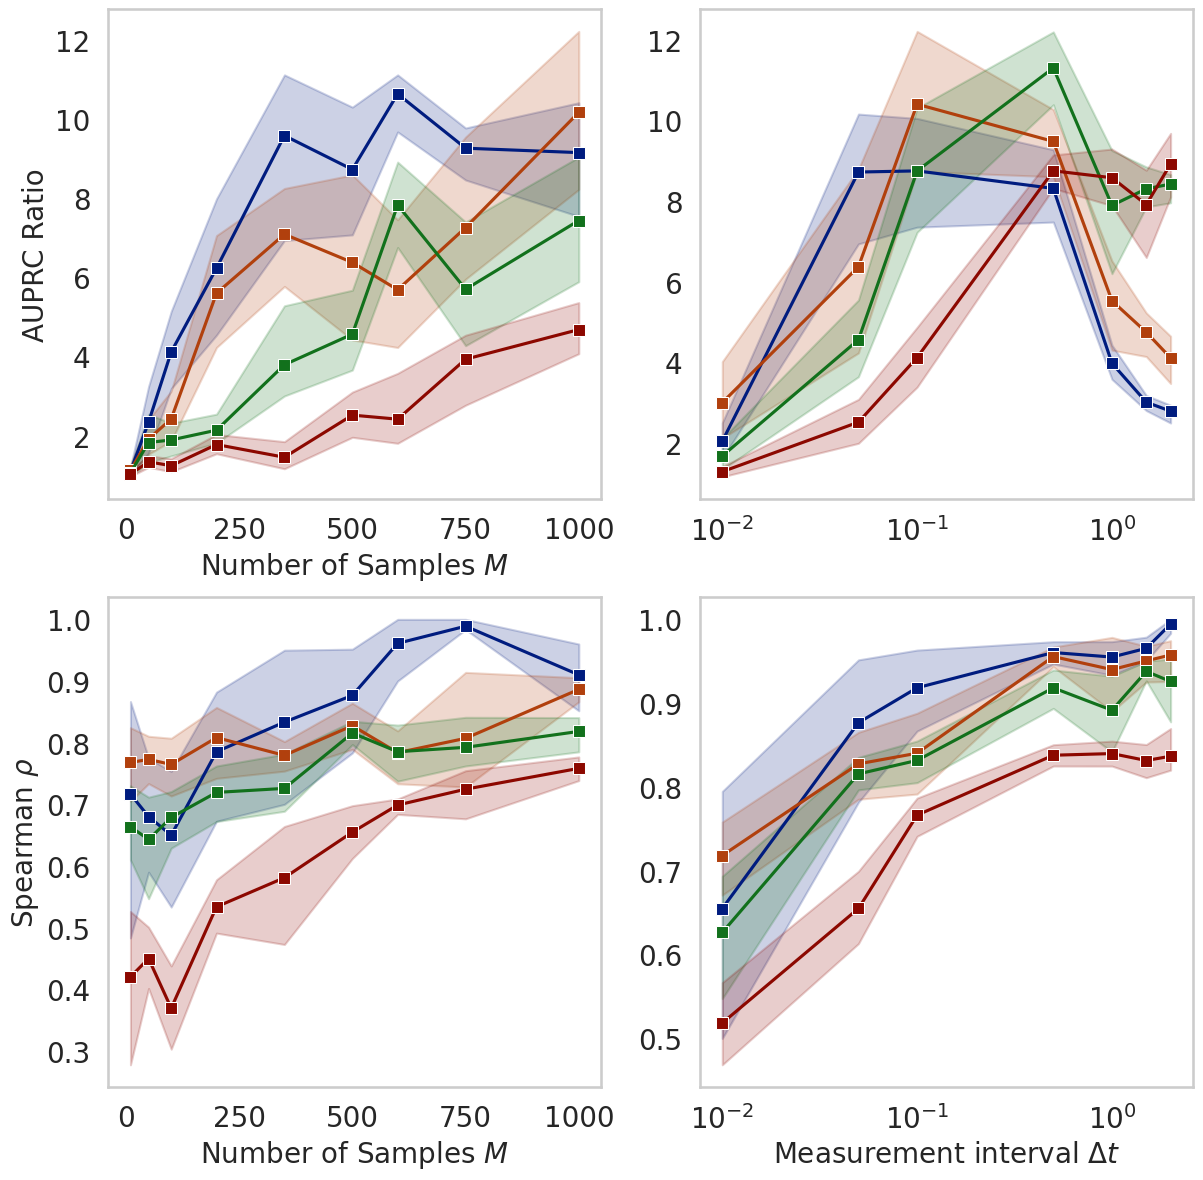

In [24]:
# Choose a specific configuration: M_pairs=500, Regime=Transient
fixed_Regime = 'T'
fixed_p = 0.15

fig, ax = plt.subplots(2,2,figsize=(14, 14))
ax = ax.flatten()
fontsize=20
if network_type == "ER":
    sns.lineplot(err_style='band', data=df[(df['p'] == fixed_p) & (df['dt_meas'] == 0.05) & (df['Regime'] == fixed_Regime)], 
                x='M_pairs', y='AUPRC_Ratio', hue='N', marker='s', 
                palette='dark', ax=ax[0], legend=False)
elif network_type == "SF":
    sns.lineplot(err_style='band', data=df[(df['dt_meas'] == 0.05) & (df['Regime'] == fixed_Regime)], 
                x='M_pairs', y='AUPRC_Ratio', hue='N', marker='s', 
                palette='dark', ax=ax[0], legend=False)
ax[0].set_xlabel(r'Number of Samples $M$', fontsize=fontsize)
ax[0].set_ylabel('AUPRC Ratio', fontsize=fontsize)
ax[0].tick_params(which='both', labelsize=fontsize)
ax[0].grid(False)#lw=1, ls='--', alpha=0.5)

if network_type == "ER":
    sns.lineplot(err_style='band', data=df[(df['p'] == fixed_p) & (df['M_pairs'] == 500) & (df['Regime'] == fixed_Regime)], 
                 x='dt_meas', y='AUPRC_Ratio', hue='N', marker='s', 
                 palette='dark', ax=ax[1], legend=False)
elif network_type == "SF":
    sns.lineplot(err_style='band', data=df[(df['M_pairs'] == 500) & (df['Regime'] == fixed_Regime)], 
                 x='dt_meas', y='AUPRC_Ratio', hue='N', marker='s', 
                 palette='dark', ax=ax[1], legend=False)
ax[1].set_xlabel('', fontsize=fontsize)
ax[1].set_ylabel('', fontsize=fontsize)
ax[1].set_xscale("log")
ax[1].tick_params(which='both', labelsize=fontsize)
ax[1].grid(False)#lw=1, ls='--', alpha=0.5)

if network_type == "ER":
    sns.lineplot(err_style='band', data=df[(df['p'] == fixed_p) & (df['dt_meas'] == 0.05) & (df['Regime'] == fixed_Regime)], 
                 x='M_pairs', y='Spearman', hue='N', marker='s', 
                 palette='dark', ax=ax[2], legend=False)
elif network_type == "SF":
    sns.lineplot(err_style='band', data=df[(df['dt_meas'] == 0.05) & (df['Regime'] == fixed_Regime)], 
                 x='M_pairs', y='Spearman', hue='N', marker='s', 
                 palette='dark', ax=ax[2], legend=False)
ax[2].set_xlabel(r'Number of Samples $M$', fontsize=fontsize)
ax[2].set_ylabel(r'Spearman $\rho$', fontsize=fontsize)
ax[2].tick_params(which='both', labelsize=fontsize)
ax[2].grid(False)#lw=1, ls='--', alpha=0.5)

if network_type == "ER":
    sns.lineplot(err_style='band', data=df[(df['p'] == fixed_p) & (df['M_pairs'] == 500) & (df['Regime'] == fixed_Regime)], 
                 x='dt_meas', y='Spearman', hue='N', marker='s', 
                 palette='dark', ax=ax[3], legend=False)
elif network_type == "SF":
    sns.lineplot(err_style='band', data=df[(df['M_pairs'] == 500) & (df['Regime'] == fixed_Regime)], 
                 x='dt_meas', y='Spearman', hue='N', marker='s', 
                 palette='dark', ax=ax[3], legend=False)
ax[3].set_xlabel(r'Measurement interval $\Delta t$', fontsize=fontsize)
ax[3].set_ylabel('', fontsize=fontsize)
ax[3].tick_params(which='both', labelsize=fontsize)
ax[3].set_xscale("log")
ax[3].grid(False)#lw=1, ls='--', alpha=0.5)

#ax.set_title(f'Impact of dt_meas on F1-Score (Fixed M={fixed_M}, Regime={fixed_Regime})')
#ax.set_xscale('log')
#ax.set_xticks([0.01, 0.05, 0.1, 0.5])
ax[0].get_xaxis().set_major_formatter(plt.ScalarFormatter())
#plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('images/detailed/impact_of_dt_fixed.png', dpi=300, bbox_inches='tight')
plt.show()


In [10]:
heatmap_data.iloc[0,0] = 0.4
heatmap_data

dt_meas,0.01,0.05,0.10,0.50,1.00,1.50
M_pairs,,,,,,
10,0.400000,0.683438,0.667460,0.795238,0.720635,0.792564
50,0.751587,0.761111,0.822222,0.785714,0.832540,0.828571
100,0.896825,0.808730,0.879365,0.898413,0.842063,0.815079
200,0.843651,0.801587,0.945238,0.912698,0.817460,0.850000
350,0.878571,0.860317,0.956349,0.980952,0.956349,0.941270
500,0.910317,0.875952,0.965079,0.980952,0.947619,0.958730
600,0.846423,0.919048,0.961905,0.980952,0.986508,0.938095
750,0.863492,0.943651,0.959524,0.956349,0.977778,0.856349
1000,0.852381,0.973016,0.961905,0.955556,0.983333,0.961905


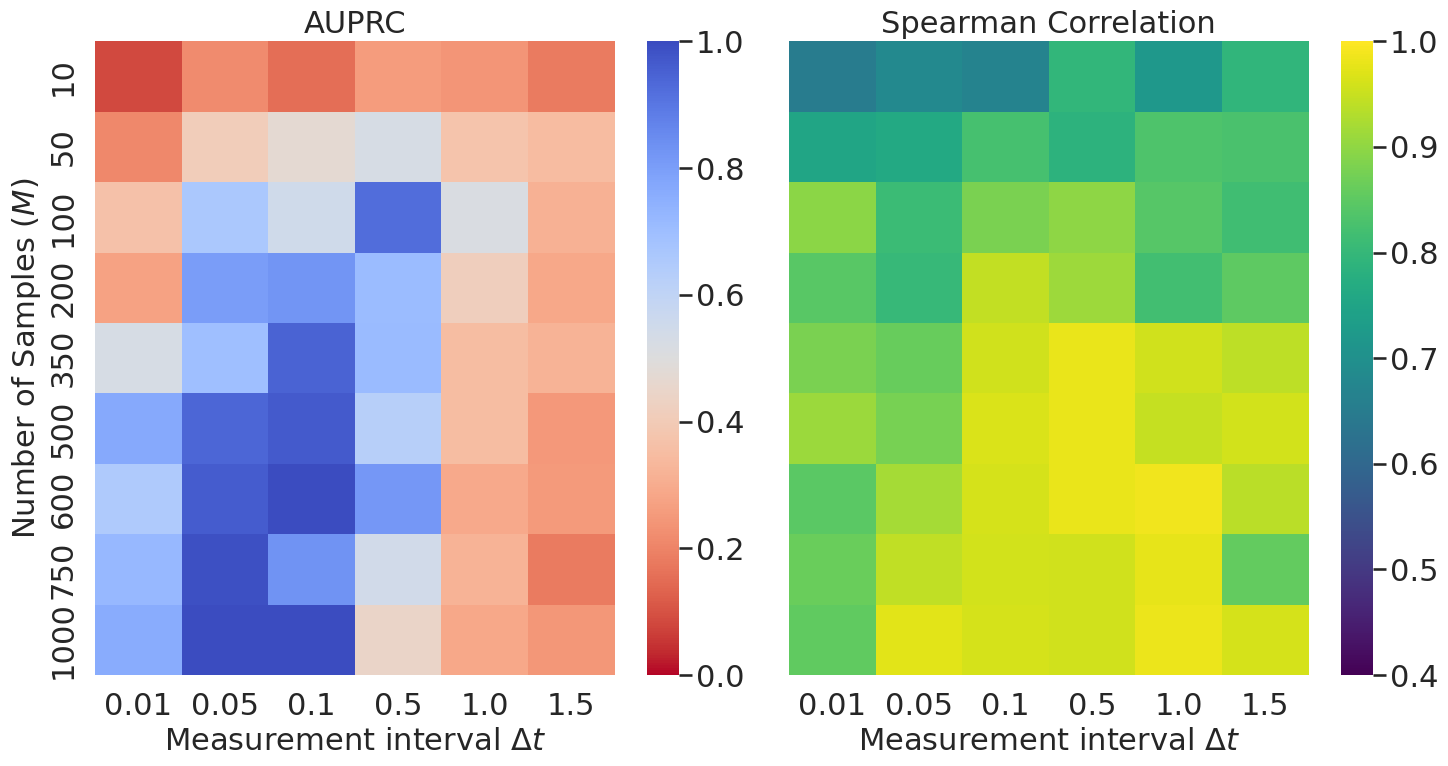

In [14]:
# plot heatmpas of MAE vs dt_meas and M_pairs for fixed N and Regime
fixed_Regime = 'T'
fixed_N = 10
if network_type == "ER":
    df_subset = df[(df['Regime'] == fixed_Regime) & (df['N'] == fixed_N) & (df['p'] == 0.15)]
elif network_type == "SF":
    df_subset = df[(df['Regime'] == fixed_Regime) & (df['N'] == fixed_N)]

fig, axs = plt.subplots(1,2,figsize=(15, 8))
fontsize=22

ax = axs[0]
heatmap_data = df_subset.pivot_table(index='M_pairs', columns='dt_meas', values='AUPRC')
sns.heatmap(heatmap_data, annot=False, fmt=".2f", cmap='coolwarm_r', cbar_kws={'label': ''}, ax=ax, vmin=0, vmax=1)
ax.collections[0].colorbar.ax.tick_params(labelsize=fontsize)
ax.set_title(f'AUPRC', fontsize=fontsize)
ax.set_xlabel(r'Measurement interval $\Delta t$', fontsize=fontsize)
ax.set_ylabel(r'Number of Samples ($M$)', fontsize=fontsize)
ax.tick_params(which='both', labelsize=fontsize)

ax = axs[1]
heatmap_data = df_subset.pivot_table(index='M_pairs', columns='dt_meas', values='Spearman')
heatmap_data.iloc[0,0] = 0.65
sns.heatmap(heatmap_data, annot=False, fmt=".2f", cmap='viridis', cbar_kws={'label': ''}, ax=ax, vmin=.4, vmax=1)
ax.collections[0].colorbar.ax.tick_params(labelsize=fontsize)
ax.set_title(f'Spearman Correlation', fontsize=fontsize)
ax.set_xlabel(r'Measurement interval $\Delta t$', fontsize=fontsize)
ax.set_ylabel('')
ax.set_yticklabels([])
ax.tick_params(which='both', labelsize=fontsize)

plt.tight_layout()

plt.show()